*  Record two different sounds  
*  Compute their spectral characteristics (spectrum, MFCC, GFCC)  
*  Build a spectrogram  
*  Analyze their similarities and differences  

In [53]:

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import sounddevice as sd
from scipy.io import wavfile
from scipy import signal
from pydub import AudioSegment
from scipy.fft import fft, fftfreq, rfft, rfftfreq, dct
import librosa
from python_speech_features import mfcc, logfbank

In [28]:
f1 = 'data/Casio-CTK-611-Bird.wav'
f2 = 'data/Casio-CTK-611-Halo-Pad-C4.wav'
samplerate1, data1 = wavfile.read(f1)
print('Bird Sampling Rate:',samplerate1)
print('Bird Audio Shape:',np.shape(data1))
samplerate2, data2 = wavfile.read(f2)
print('Halo Sampling Rate:',samplerate2)
print('Halo Audio Shape:',np.shape(data2))

Bird Sampling Rate: 44100
Bird Audio Shape: (145609, 2)
Halo Sampling Rate: 44100
Halo Audio Shape: (144190, 2)


C:\Users\krapa\AppData\Local\Temp\ipykernel_4204\2539297439.py:3: WavFileWarning: Chunk (non-data) not understood, skipping it.
  samplerate1, data1 = wavfile.read(f1)
C:\Users\krapa\AppData\Local\Temp\ipykernel_4204\2539297439.py:6: WavFileWarning: Chunk (non-data) not understood, skipping it.
  samplerate2, data2 = wavfile.read(f2)


In [49]:
if data1.ndim > 1:
        data1 = data1.mean(axis=1)
if data2.ndim > 1:
        data2 = data2.mean(axis=1)
    
duration1 = len(data1) / samplerate1
time1 = np.arange(0,duration1,1/ samplerate1) 
duration2 = len(data2) / samplerate2
time2 = np.arange(0,duration2,1 / samplerate2) 

print(f"1 файл длительность {duration1} \n временная шкала {time1}")

print(f"2 файл длительность {duration2} \n временная шкала {time2}")

1 файл длительность 3.3017913832199546 
 временная шкала [0.00000000e+00 2.26757370e-05 4.53514739e-05 ... 3.30172336e+00
 3.30174603e+00 3.30176871e+00]
2 файл длительность 3.269614512471655 
 временная шкала [0.00000000e+00 2.26757370e-05 4.53514739e-05 ... 3.26954649e+00
 3.26956916e+00 3.26959184e+00]


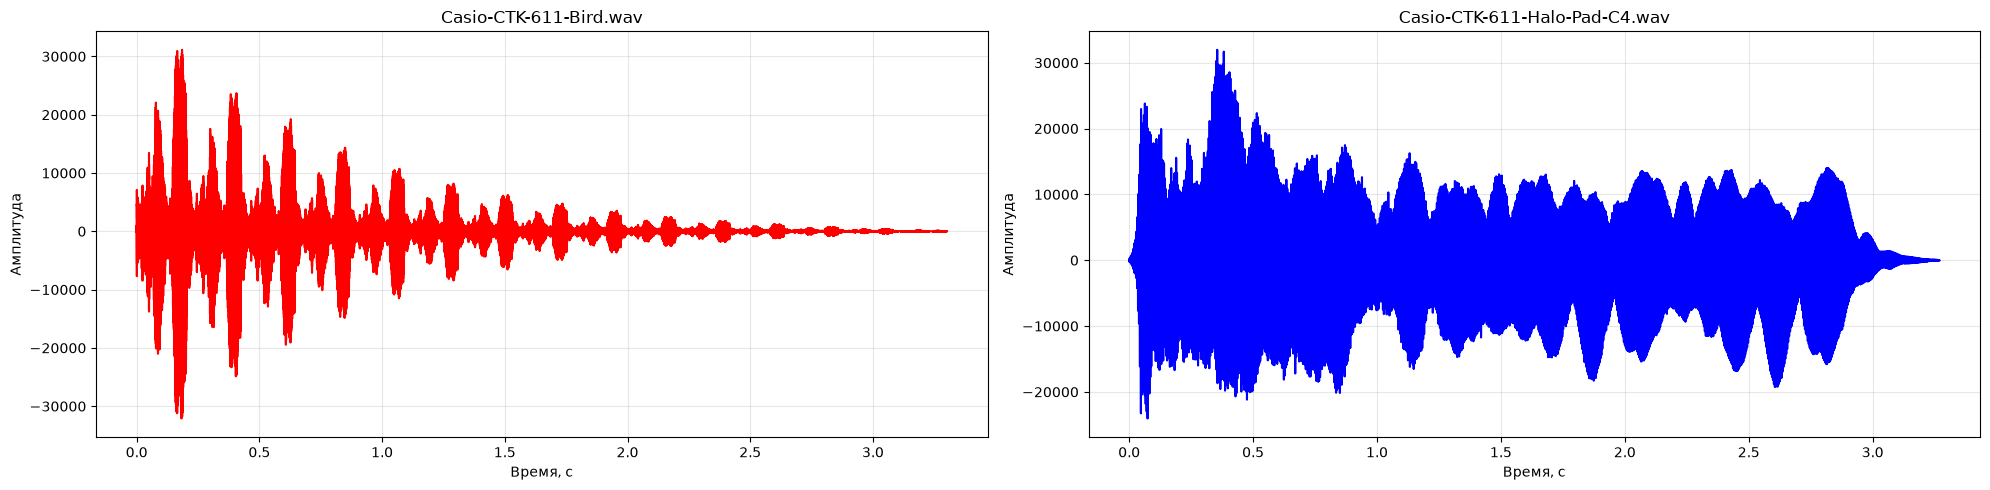

In [30]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 2, 1)
plt.plot(time1, data1, color='red')
plt.xlabel('Время, с')
plt.ylabel('Амплитуда')
plt.title('Casio-CTK-611-Bird.wav')
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(time2, data2, color='blue')
plt.xlabel('Время, с')
plt.ylabel('Амплитуда')
plt.title('Casio-CTK-611-Halo-Pad-C4.wav')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

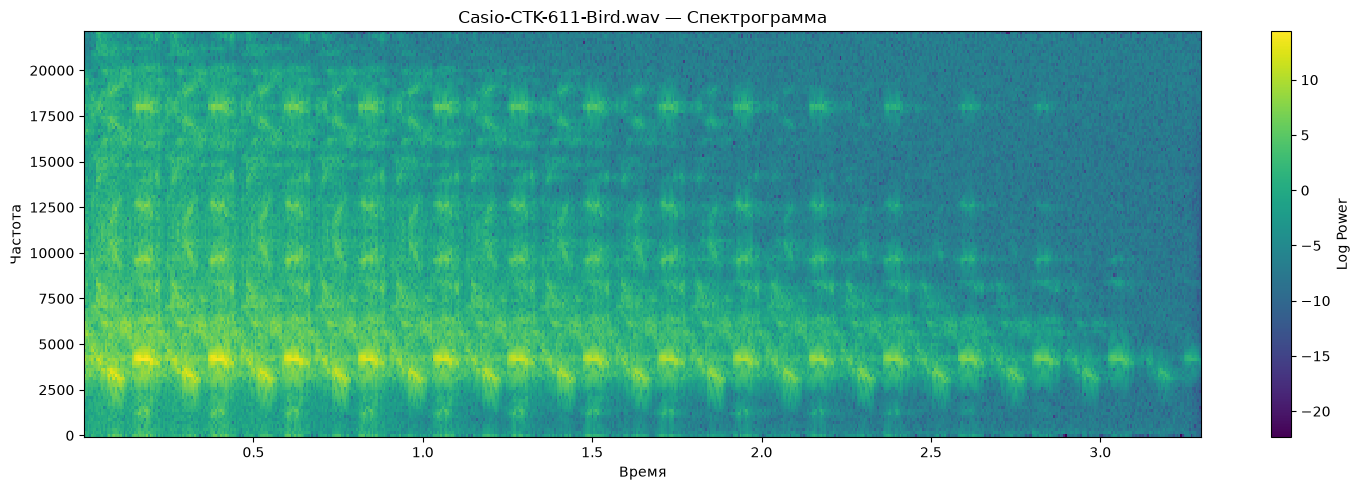

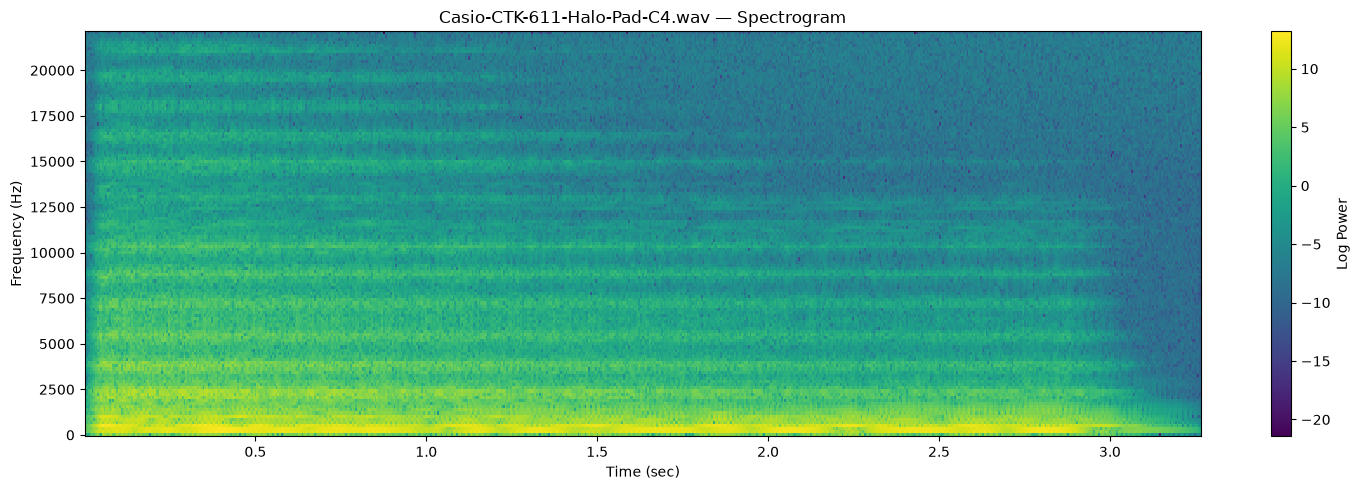

In [ ]:
adata1 = data1
s1 = samplerate1
fr1, tm1, spgram1 = signal.spectrogram(adata1, s1)
lspg1 = np.log(spgram1 + 1e-10)
adata2 = data2
s2 = samplerate2
fr2, tm2, spgram2 = signal.spectrogram(adata2, s2)
lspg2 = np.log(spgram2 + 1e-10)

plt.figure(figsize=(15, 5))
plt.pcolormesh(tm1, fr1, lspg1, shading='auto')
plt.ylabel('Частота')
plt.xlabel('Время')
plt.title('Casio-CTK-611-Bird.wav Спектрограмма')
plt.colorbar(label='Log Power')
plt.tight_layout()
plt.show()


plt.figure(figsize=(15, 5))
plt.pcolormesh(tm2, fr2, lspg2, shading='auto')
plt.ylabel('Frequency (Hz)')
plt.xlabel('Time (sec)')
plt.title('Casio-CTK-611-Halo-Pad-C4.wav Spectrogram')
plt.colorbar(label='Log Power')
plt.tight_layout()
plt.show()

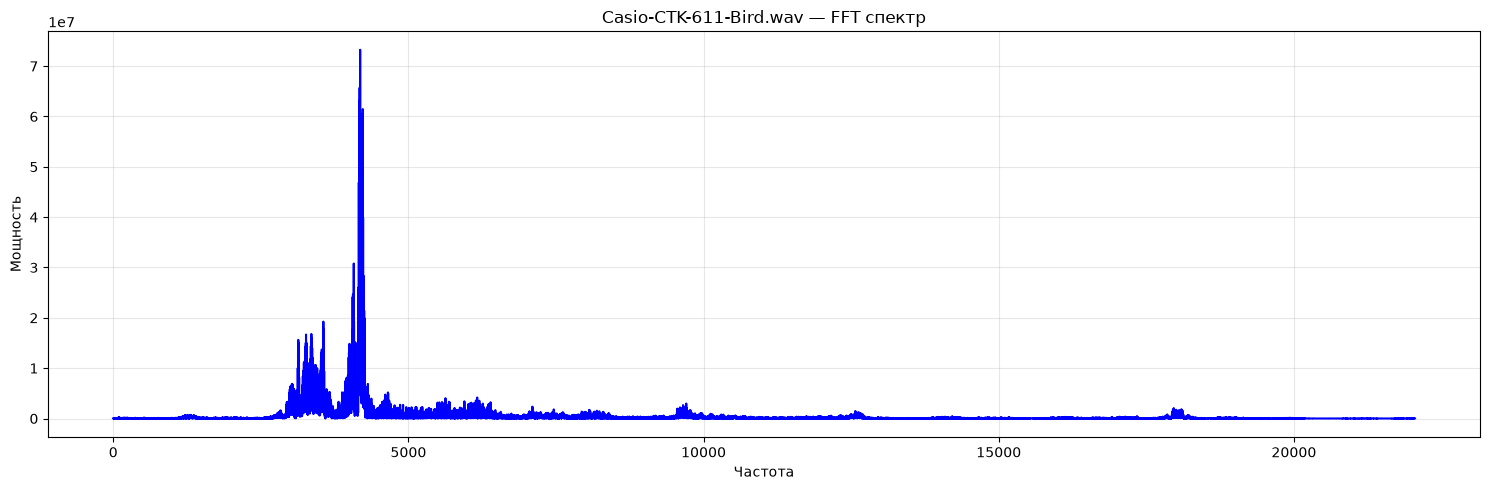

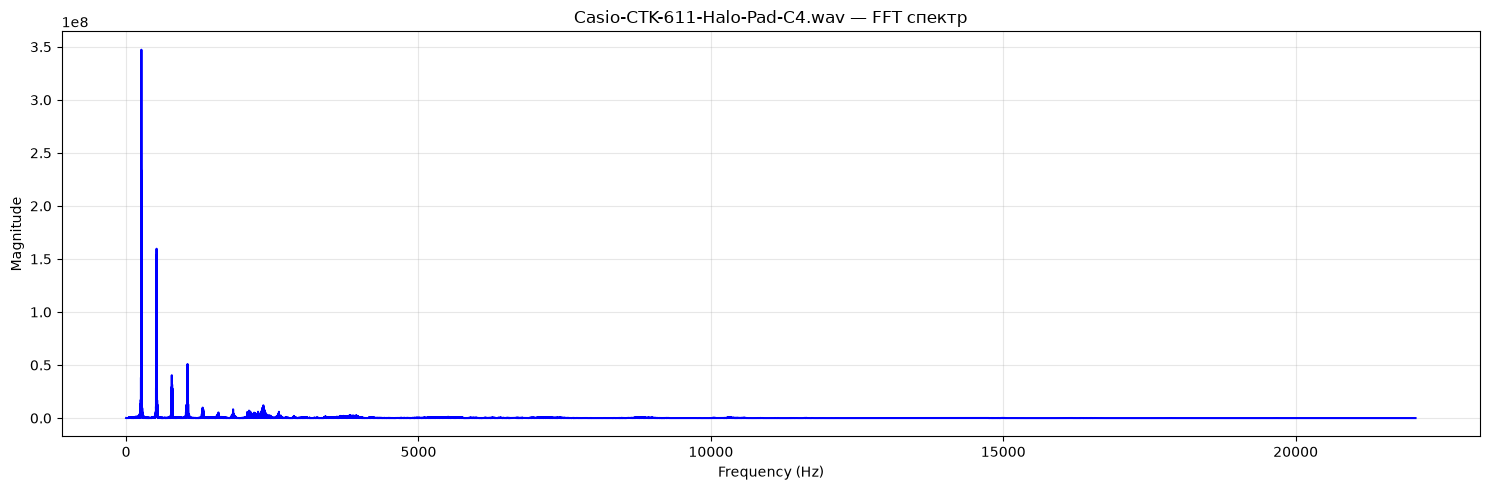

In [ ]:
N1 = len(data1)
yf1 = rfft(data1)
xf1 = rfftfreq(N1, 1 / samplerate1)

N2 = len(data2)
yf2 = rfft(data2)
xf2 = rfftfreq(N2, 1 / samplerate2)

plt.figure(figsize=(15, 5))
plt.plot(xf1, np.abs(yf1), color='blue')
plt.xlabel('Частота')
plt.ylabel('Мощность')
plt.title('Casio-CTK-611-Bird.wav FFT спектр')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 5))
plt.plot(xf2, np.abs(yf2), color='blue')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.title('Casio-CTK-611-Halo-Pad-C4.wav FFT спектр')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

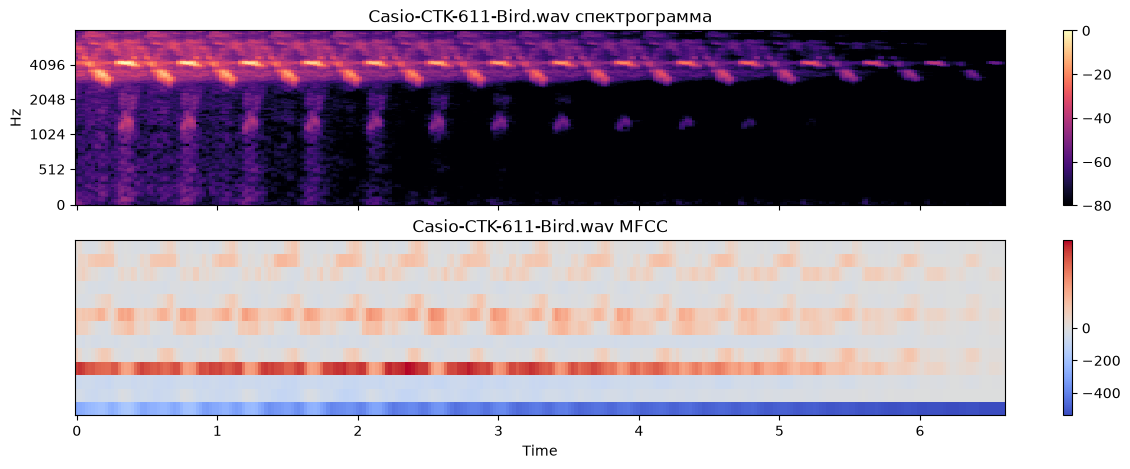

In [40]:
y1, sr1 = librosa.load(f1, sr=None)
mfccs1 = librosa.feature.mfcc(y=y1, sr=sr1, n_mfcc=13)
S1 = librosa.feature.melspectrogram(y=y1, sr=sr1, n_mels=128, fmax=8000)

fig, ax = plt.subplots(nrows=2, sharex=True, figsize=(15, 5))
img1 = librosa.display.specshow(librosa.power_to_db(S1, ref=np.max),x_axis='time', y_axis='mel', fmax=8000,ax=ax[0])
fig.colorbar(img1, ax=[ax[0]])
ax[0].set(title='Casio-CTK-611-Bird.wav спектрограмма')
ax[0].label_outer()

img2 = librosa.display.specshow(mfccs1, x_axis='time', ax=ax[1])
fig.colorbar(img2, ax=[ax[1]])
ax[1].set(title='Casio-CTK-611-Bird.wav MFCC')
plt.show()

In [46]:
mfccs1

array([[-2.9254889e+02, -2.8059406e+02, -2.6986945e+02, ...,
        -5.3569257e+02, -5.3691290e+02, -5.3886456e+02],
       [-3.6209824e+01, -3.9710102e+01, -4.7962898e+01, ...,
        -2.0665395e+00, -1.5445130e+00, -7.1123105e-01],
       [-6.9645447e+01, -6.3647224e+01, -5.8340683e+01, ...,
        -5.6352277e+00, -4.2265291e+00, -1.9713395e+00],
       ...,
       [ 7.6653080e+00,  1.1573543e+01,  1.6422970e+01, ...,
         6.7434449e+00,  5.0573483e+00,  2.3514199e+00],
       [ 2.1455312e+00,  1.2404867e+01,  1.2050447e+01, ...,
        -1.4359025e+00, -1.0368416e+00, -4.1354340e-01],
       [ 5.2569561e+00,  6.4984522e+00, -5.7241373e+00, ...,
        -5.8365240e+00, -4.4063530e+00, -2.0956960e+00]],
      shape=(13, 285), dtype=float32)

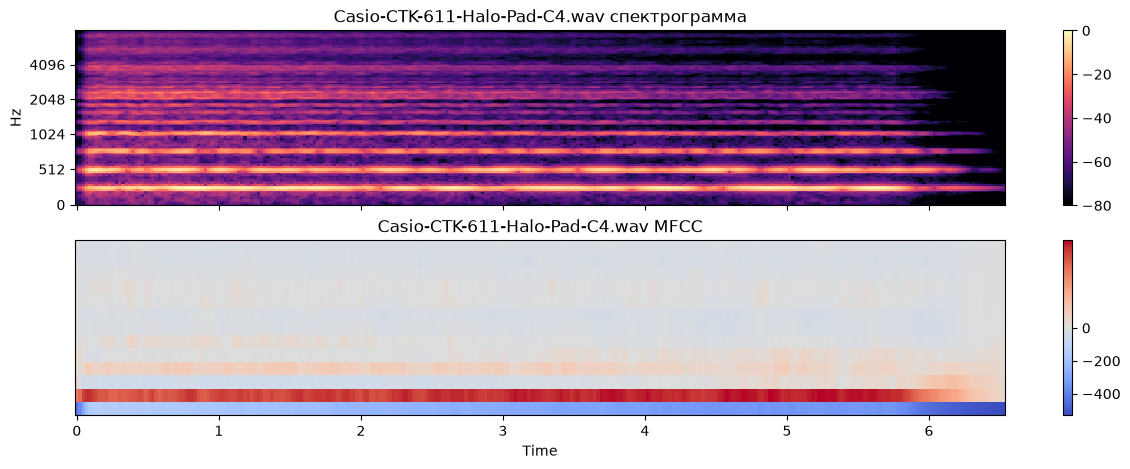

In [41]:
y2, sr2 = librosa.load(f2, sr=None)
mfccs2 = librosa.feature.mfcc(y=y2, sr=sr2, n_mfcc=13)
S2 = librosa.feature.melspectrogram(y=y2, sr=sr2, n_mels=128, fmax=8000)

fig, ax = plt.subplots(nrows=2, sharex=True, figsize=(15, 5))
img3 = librosa.display.specshow(librosa.power_to_db(S2, ref=np.max),x_axis='time', y_axis='mel', fmax=8000, ax=ax[0])
fig.colorbar(img3, ax=[ax[0]])
ax[0].set(title='Casio-CTK-611-Halo-Pad-C4.wav спектрограмма')
ax[0].label_outer()
img4 = librosa.display.specshow(mfccs2, x_axis='time', ax=ax[1])
fig.colorbar(img4, ax=[ax[1]])
ax[1].set(title='Casio-CTK-611-Halo-Pad-C4.wav MFCC')
plt.show()

In [43]:
mfccs2

array([[-439.537    , -371.71677  , -286.4632   , ..., -526.6842   ,
        -529.3346   , -532.438    ],
       [  95.54871  ,  106.18885  ,  131.2768   , ...,   19.55669  ,
          16.071014 ,   12.03419  ],
       [  21.925825 ,  -16.448042 ,  -41.63646  , ...,   17.138683 ,
          14.389345 ,   11.345381 ],
       ...,
       [  -5.216234 ,   -6.541648 ,  -10.822235 , ...,   -8.048665 ,
          -6.5959225,   -4.1154633],
       [ -21.272522 ,  -18.098246 ,  -21.519344 , ...,   -8.242364 ,
          -7.3825684,   -6.0919085],
       [ -21.740303 ,  -16.101048 ,  -16.92032  , ...,   -8.084894 ,
          -7.819936 ,   -7.8020177]], shape=(13, 282), dtype=float32)

In [ ]:
def compute_gfcc_framed(audio, sr, numcep=22, nfilt=32, winlen=0.025, winstep=0.01, preemph=0.97):
 
    win_length = int(round(winlen * sr))
    hop_length = int(round(winstep * sr))
    
    audio = np.asarray(audio, dtype=np.float64)
    
    n_frames = 1 + (audio.size - win_length) // hop_length
    idx = (
        np.arange(win_length)[None, :]
        + hop_length * np.arange(n_frames)[:, None]
    )
    window = np.hamming(win_length)
    frames = audio[idx] * window[None, :]
    
    spectrum = np.abs(rfft(frames, axis=1)) ** 2
    freqs = rfftfreq(win_length, 1/sr)
    
    def erb(f): return 21.366 * np.log(1 + f / 700)
    def inv_erb(z): return 700 * (np.exp(z / 21.366) - 1)
    
    erb_edges = np.linspace(erb(0.0), erb(sr / 2), nfilt + 2)
    freq_edges = inv_erb(erb_edges)

    filters = np.zeros((nfilt, freqs.size))
    for i in range(nfilt):
        left, center, right = freq_edges[i], freq_edges[i + 1], freq_edges[i + 2]

        rise = (freqs >= left) & (freqs <= center)
        fall = (freqs > center) & (freqs <= right)

        filters[i, rise] = (freqs[rise] - left) / (center - left + 1e-12)
        filters[i, fall] = (right - freqs[fall]) / (right - center + 1e-12)


    energies = np.dot(filters, spectrum.T).T + 1e-10
    log_energies = np.log(energies)

    gfcc = dct(log_energies, type=2, norm='ortho', axis=1)[:, :numcep]
    
    return gfcc

gfcc1_framed = compute_gfcc_framed(data1, samplerate1)
gfcc2_framed = compute_gfcc_framed(data2, samplerate2)

print('Casio-CTK-611-Bird.wav GFCC:', gfcc1_framed.shape)
print('Casio-CTK-611-Halo-Pad-C4.wav GFCC:', gfcc2_framed.shape)

Casio-CTK-611-Bird.wav GFCC: (328, 22)
Casio-CTK-611-Halo-Pad-C4.wav GFCC: (325, 22)


In [54]:
(rate1, data1) = wavfile.read(f1)
if data1.ndim > 1:
        data1 = data1.mean(axis=1)

mfcc_feat1 = mfcc(data1, rate1, numcep=13)
fbank_feat1 = logfbank(data1, rate1, nfilt=40)

(rate2, data2) = wavfile.read(f2)
if data2.ndim > 1:
        data2 = data2.mean(axis=1)
mfcc_feat2 = mfcc(data2, rate2, numcep=13)
fbank_feat2 = logfbank(data2, rate2, nfilt=40)


C:\Users\krapa\AppData\Local\Temp\ipykernel_4204\1427188594.py:1: WavFileWarning: Chunk (non-data) not understood, skipping it.
  (rate1, data1) = wavfile.read(f1)
C:\Users\krapa\AppData\Local\Temp\ipykernel_4204\1427188594.py:8: WavFileWarning: Chunk (non-data) not understood, skipping it.
  (rate2, data2) = wavfile.read(f2)


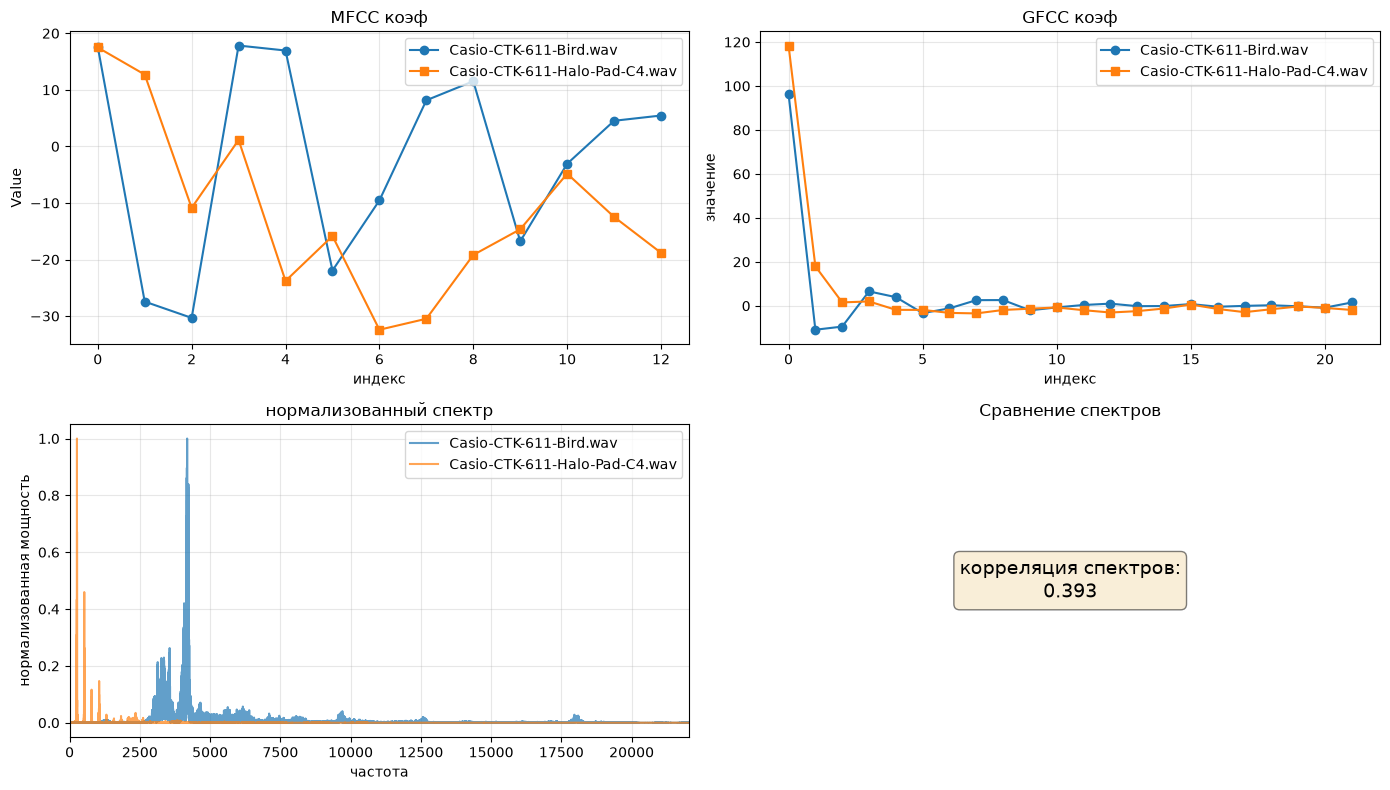

In [56]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].plot(np.mean(mfcc_feat1, axis=0), label='Casio-CTK-611-Bird.wav', marker='o')
axes[0, 0].plot(np.mean(mfcc_feat2, axis=0), label='Casio-CTK-611-Halo-Pad-C4.wav', marker='s')
axes[0, 0].set_title('MFCC коэф')
axes[0, 0].set_xlabel('индекс')
axes[0, 0].set_ylabel('Value')
axes[0, 0].grid(alpha=0.3)
axes[0, 0].legend()                                   

axes[0, 1].plot(np.mean(gfcc1_framed, axis=0), label='Casio-CTK-611-Bird.wav', marker='o')
axes[0, 1].plot(np.mean(gfcc2_framed, axis=0), label='Casio-CTK-611-Halo-Pad-C4.wav', marker='s')
axes[0, 1].set_title('GFCC коэф')                      
axes[0, 1].set_xlabel('индекс')
axes[0, 1].set_ylabel('значение')
axes[0, 1].grid(alpha=0.3)
axes[0, 1].legend()                                    

axes[1, 0].plot(xf1, np.abs(yf1) / (np.max(np.abs(yf1)) + 1e-10),
                label='Casio-CTK-611-Bird.wav', alpha=0.7)
axes[1, 0].plot(xf2, np.abs(yf2) / (np.max(np.abs(yf2)) + 1e-10),
                label='Casio-CTK-611-Halo-Pad-C4.wav', alpha=0.7)
axes[1, 0].set_title('нормализованный спектр')
axes[1, 0].set_xlabel('частота')
axes[1, 0].set_ylabel('нормализованная мощность')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)
axes[1, 0].set_xlim(0, min(samplerate1, samplerate2) / 2)

f_max = min(samplerate1, samplerate2) / 2
common_freq = np.linspace(0, f_max, 1000)
spec1_interp = np.interp(common_freq, xf1, np.abs(yf1))
spec2_interp = np.interp(common_freq, xf2, np.abs(yf2))
corr = np.corrcoef(np.log(spec1_interp + 1e-10),
                   np.log(spec2_interp + 1e-10))[0, 1]
axes[1, 1].text(0.5, 0.5, f'корреляция спектров:\n{corr:.3f}',
                ha='center', va='center', fontsize=14,
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
axes[1, 1].set_title('Сравнение спектров')
axes[1, 1].axis('off')                                

plt.tight_layout()
plt.show()